In [58]:
import pathlib
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 


%matplotlib inline


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f/remapping_w_dark')
sess_df = pd.read_csv(basedir / 'sessions.csv')
sess_df = sess_df[sess_df['usable'] == 1]
# sess_df = sess_df.iloc[:-1]
print(sess_df.columns)
sess_df['fly_id'] = [row['date']+'_'+row['fly'] +'_' + row['condition'] for _, row in sess_df.iterrows()]
sess_df['mean offset'] = [np.nan for _, row in sess_df.iterrows()]
sess_df['offset var.'] = [np.nan for _, row in sess_df.iterrows()]
sess_df['mean vec. len'] = [np.nan for _, row in sess_df.iterrows()]


figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/R18B05LexA_CsChrimsontdT_R60D05Gal4_jGCaMP7f')
figfolder.mkdir(parents=True, exist_ok=True)

Index(['date', 'fly', 'sess', 'fictrac_scan_num', 'fictrac_file', 'condition',
       'scan_type', 'post_dark', 'usable', 'notes'],
      dtype='str')


In [60]:
sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,post_dark,usable,notes,fly_id,mean offset,offset var.,mean vec. len
5,22_04_2026,fly3,baseline-001,1,fictrac-20260422_115036.dat,replication,baseline,0,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
6,22_04_2026,fly3,remap_180deg-003,3,fictrac-20260422_115036.dat,replication,remap_180deg,0,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
7,22_04_2026,fly3,post_180deg-005,5,fictrac-20260422_115036.dat,replication,post_180deg,0,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
8,22_04_2026,fly3,remap_0deg_wdark-006,6,fictrac-20260422_115036.dat,replication,remap_0deg,1,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
9,22_04_2026,fly3,post_0deg_wdark-007,7,fictrac-20260422_115036.dat,replication,post_0deg,1,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN


In [61]:
load_row = nmp.loading.make_load_row(basedir, folder_cols=('condition',))

In [62]:
opto_responses = {
   'remap_0deg': [], 
   'remap_180deg': [], 
   'combined':[],
}
   

##
sess_df_remap0 = sess_df.loc[sess_df['scan_type']=='remap_0deg']
remap = sess_df_remap0.loc[sess_df_remap0['condition']=='replication']
opto_responses['remap_0deg'] = np.stack([nmp.remapping.get_opto_resp(load_row(row)) for _, row in remap.iterrows()])

##
sess_df_remap180 = sess_df.loc[sess_df['scan_type']=='remap_180deg']
remap = sess_df_remap180.loc[sess_df_remap180['condition']=='replication']
opto_responses['remap_180deg'] = np.stack([nmp.remapping.get_opto_resp(load_row(row)) for _, row in remap.iterrows()])

opto_responses['combined'] = (opto_responses['remap_0deg'] + opto_responses['remap_180deg'])/2


Text(0.5, 1.0, 'Remap: remap pi')

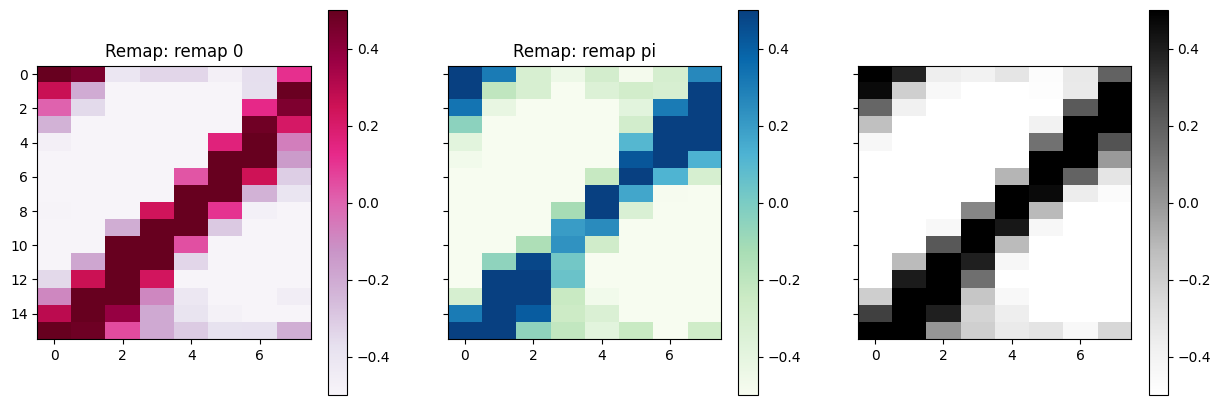

In [63]:
fig, ax = plt.subplots(1,3,figsize=[15,5],sharex=True,sharey=True)
h = ax[0].imshow(np.nanmean(opto_responses['remap_0deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='PuRd')
fig.colorbar(h, ax=ax[0])
h = ax[1].imshow(np.nanmean(opto_responses['remap_180deg'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='GnBu')
fig.colorbar(h, ax=ax[1])
h = ax[2].imshow(np.nanmean(opto_responses['combined'],axis=(0,3)),aspect=.5, vmin=-.5, vmax=.5, cmap='Greys')
fig.colorbar(h, ax=ax[2])

ax[0].set_title('Remap: remap 0')
ax[1].set_title('Remap: remap pi')


In [64]:
nonremap_sess_df = sess_df.loc[(sess_df['scan_type']=='baseline') | \
                               (sess_df['scan_type']=='post_0deg') | \
                               (sess_df['scan_type']=='post_180deg') | \
                               (sess_df['scan_type']=='post_novis1') | \
                               (sess_df['scan_type']=='post_novis2')]
flies = nonremap_sess_df['fly_id'].unique()
for index,row in nonremap_sess_df.iterrows():
    ts = nmp.session.GetTS(load_row(row))
    
    
    offset_c_mu = ts.offset_c.mean()
    
    sess_df.loc[index, 'mean offset'] = np.angle(offset_c_mu)
    sess_df.loc[index, 'mean vec. len'] = np.abs(offset_c_mu)
    sess_df.loc[index, 'offset var.'] = sp.stats.circvar(ts.offset)

/tmp/ipykernel_967551/1313351860.py:8: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.stripplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, alpha=.5,


(0.0, 1.0)

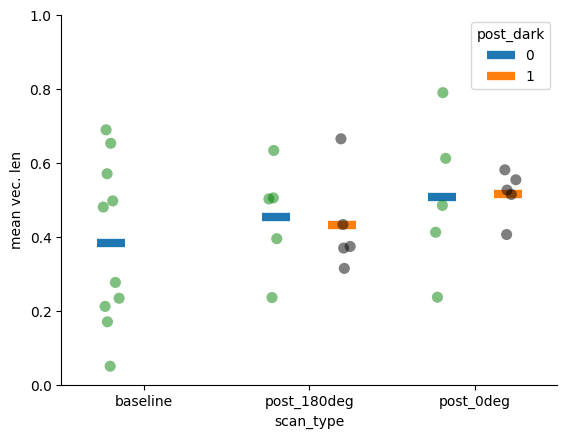

In [65]:
import seaborn as sns
fig, ax = plt.subplots()

colors = ['green', 'black', plt.cm.Greys(.6)]
tmp_sess_df = sess_df.loc[sess_df['scan_type'].isin(('baseline', 'post_0deg', 'post_180deg', 'post_novis1', 'post_novis2'))]
# tmp_sess_df = tmp_sess_df.loc[tmp_sess_df['condition'].isin(('remap', 'no_chrimson', 'novis_control'))]

sns.stripplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, alpha=.5,
            dodge=True, palette=colors, hue='post_dark', s=8, legend=False,
            )
sns.pointplot(data=tmp_sess_df, x='scan_type', y='mean vec. len', ax=ax, 
              hue='post_dark',
              estimator=np.mean, errorbar=None, marker='_', markersize=20, 
              markeredgewidth=6, legend=True, dodge=.4, linestyle='none')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim([0,1])
# fig.savefig(figfolder / "remapping_vec_len_comparison.pdf")


In [66]:
sess_df.loc[sess_df['fly_id']==flies[0]]

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,post_dark,usable,notes,fly_id,mean offset,offset var.,mean vec. len
5,22_04_2026,fly3,baseline-001,1,fictrac-20260422_115036.dat,replication,baseline,0,1,NaN,22_04_2026_fly3_replication,0.071337,0.788423,0.211577
6,22_04_2026,fly3,remap_180deg-003,3,fictrac-20260422_115036.dat,replication,remap_180deg,0,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
7,22_04_2026,fly3,post_180deg-005,5,fictrac-20260422_115036.dat,replication,post_180deg,0,1,NaN,22_04_2026_fly3_replication,-2.706180,0.494889,0.505111
8,22_04_2026,fly3,remap_0deg_wdark-006,6,fictrac-20260422_115036.dat,replication,remap_0deg,1,1,NaN,22_04_2026_fly3_replication,NaN,NaN,NaN
9,22_04_2026,fly3,post_0deg_wdark-007,7,fictrac-20260422_115036.dat,replication,post_0deg,1,1,NaN,22_04_2026_fly3_replication,0.054692,0.418960,0.581040


In [68]:
flies

<ArrowStringArray>
['22_04_2026_fly3_replication', '23_04_2026_fly1_replication',
 '23_04_2026_fly3_replication', '27_04_2026_fly1_replication',
 '27_04_2026_fly2_replication', '27_04_2026_fly3_replication',
 '28_04_2026_fly1_replication', '04_05_2026_fly1_replication',
 '04_05_2026_fly2_replication', '04_05_2026_fly3_replication']
Length: 10, dtype: str

In [69]:

sum_stats = nmp.remapping.build_sum_stats(sess_df, flies, scan_types=nmp.remapping.STANDARD_SCAN_TYPES, extra_metrics=('post_dark',))

In [71]:
sum_stats

,fly_id,baseline mean offset,baseline vec. len,baseline offset var.,baseline post_dark,post_0deg mean offset,post_0deg vec. len,post_0deg offset var.,post_0deg post_dark,post_180deg mean offset,post_180deg vec. len,post_180deg offset var.,post_180deg post_dark
0,22_04_2026_fly3_replication,0.071337,0.211577,0.788423,0.0,0.054692,0.581040,0.418960,1.0,-2.706180,0.505111,0.494889,0.0
1,23_04_2026_fly1_replication,-0.169944,0.570449,0.429551,0.0,0.158000,0.412126,0.587874,0.0,-2.826651,0.369304,0.630696,1.0
2,23_04_2026_fly3_replication,1.948146,0.276321,0.723679,0.0,0.077468,0.236429,0.763571,0.0,1.852356,0.314354,0.685646,1.0
3,27_04_2026_fly1_replication,-1.300158,0.689269,0.310731,0.0,-0.622754,0.514364,0.485636,1.0,2.973668,0.633418,0.366582,0.0
4,27_04_2026_fly2_replication,-2.113391,0.233636,0.766364,0.0,0.607793,0.612076,0.387924,0.0,2.514115,0.664991,0.335009,1.0
5,27_04_2026_fly3_replication,-1.064669,0.169830,0.830170,0.0,-2.649346,0.405999,0.594001,1.0,-1.997108,0.235521,0.764479,0.0
6,28_04_2026_fly1_replication,0.387341,0.049722,0.950278,0.0,-0.356478,0.484699,0.515301,0.0,-2.797540,0.373663,0.626337,1.0
7,04_05_2026_fly1_replication,1.795963,0.496969,0.503031,0.0,0.231704,0.526301,0.473699,1.0,-2.655770,0.394780,0.605220,0.0
8,04_05_2026_fly2_replication,-1.234066,0.652739,0.347261,0.0,-0.101486,0.789861,0.210139,0.0,2.916202,0.433070,0.566930,1.0
9,04_05_2026_fly3_replication,-0.393108,0.480386,0.519614,0.0,0.490818,0.554181,0.445819,1.0,-2.949585,0.502300,0.497700,0.0


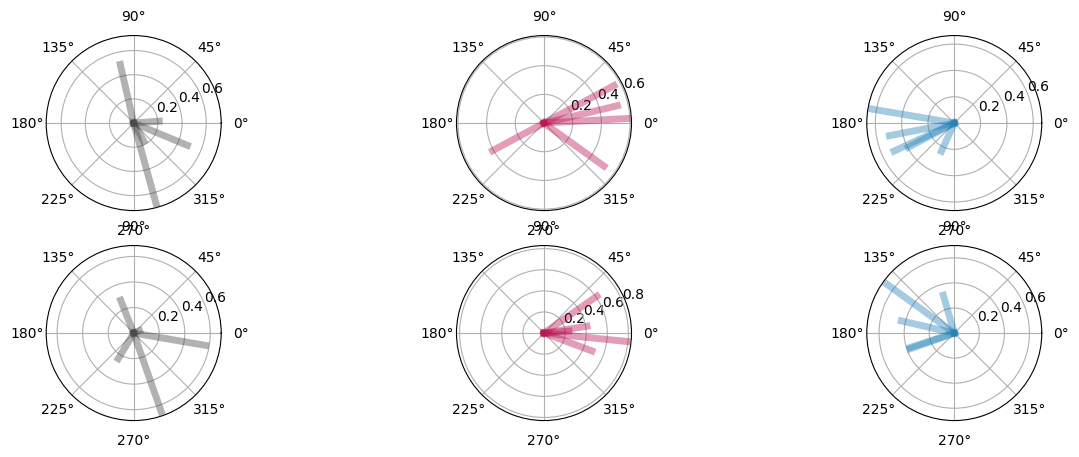

In [72]:
fig, ax = plt.subplots(2, 3, subplot_kw={'projection':'polar'}, figsize=[15,5])

for _, row in sum_stats.iterrows():
    

    if row['post_0deg post_dark'] == 1:
        ax[0,0].plot(row['baseline mean offset']*np.ones([2,]), [0, row['baseline vec. len']], color=plt.cm.Greys(.8), alpha=.4, linewidth=5)
        ax[0,1].plot(row['post_0deg mean offset']*np.ones([2,]), [0, row['post_0deg vec. len']], color=plt.cm.PuRd(.8), alpha=.4, linewidth=5)
        ax[0,2].plot(row['post_180deg mean offset']*np.ones([2,]), [0, row['post_180deg vec. len']], color=plt.cm.GnBu(.8), alpha=.4, linewidth=5)
    else:
        ax[1,0].plot(row['baseline mean offset']*np.ones([2,]), [0, row['baseline vec. len']], color=plt.cm.Greys(.8), alpha=.4, linewidth=5)
        ax[1,1].plot(row['post_0deg mean offset']*np.ones([2,]), [0, row['post_0deg vec. len']], color=plt.cm.PuRd(.8), alpha=.4, linewidth=5)
        ax[1,2].plot(row['post_180deg mean offset']*np.ones([2,]), [0, row['post_180deg vec. len']], color=plt.cm.GnBu(.8), alpha=.4, linewidth=5)

    



Wilcoxon signed-rank test: statistic=13.0, p-value=0.16015625


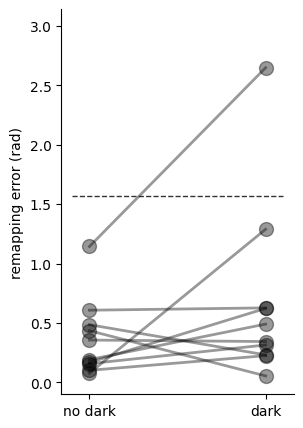

In [76]:


err = np.zeros([len(sum_stats), 2])
for i, row in sum_stats.iterrows():
    
    if row['post_0deg post_dark'] == 1:
        err[i, 1] = np.abs(row['post_0deg mean offset'])
        err[i, 0] = np.abs(np.angle(np.exp(1j*(np.pi - row['post_180deg mean offset']))))
       
    else:
        err[i, 0] = np.abs(row['post_0deg mean offset'])
        err[i, 1] = np.abs(np.angle(np.exp(1j*(np.pi - row['post_180deg mean offset']))))
        


fig, ax = plt.subplots(figsize=[3,5])
ax.plot([0,1], err.T, 'k.-', alpha=.4, linewidth=2,markersize=20)
ax.plot([-.1,1.1], np.pi/2*np.ones([2,]), 'k--', alpha=.8, linewidth=1)

ax.set_ylim([-.1, np.pi])
ax.set_xticks([0,1], labels=['no dark', 'dark'])

ax.set_ylabel('remapping error (rad)')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

t,p = sp.stats.wilcoxon(err[:,0], err[:,1])
print(f"Wilcoxon signed-rank test: statistic={t}, p-value={p}")
